# 04. Análisis de errores del módulo clásico (T44)

Qué imágenes falla el clásico, agrupadas por tipo de error (real → predicha), y **qué regla del árbol** las decidió.

Los datos se generan con `python -m src.error_analysis` a partir de `results/clasico/descriptores_*.csv` y `results/clasico/umbrales.json` (T43). Cada error se explica con la misma rama de `classic.predict`, con el descriptor que compara, su valor, el umbral y el margen (valor − umbral).

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
CLASSIC = ROOT / 'results' / 'clasico'
FIGURES = ROOT / 'results' / 'figuras'

## 1. Errores por par real → predicho

In [2]:
pd.read_csv(CLASSIC / 'errores_resumen_test.csv')

,label,pred,regla,descriptor_decisivo,n
0,girada,normal,coincide_y_giro_dentro_del_limite,angle,2
1,normal,girada,sin_coincidencias_y_nitida,lap_var,1


In [3]:
pd.read_csv(CLASSIC / 'errores_resumen_camara_no_vista.csv')

,label,pred,regla,descriptor_decisivo,n
0,girada,normal,coincide_y_giro_dentro_del_limite,angle,26
1,desenfocada,normal,coincide_y_giro_dentro_del_limite,angle,18
2,desenfocada,girada,sin_coincidencias_y_nitida,lap_var,12
3,desenfocada,girada,coincide_pero_giro_grande,angle,3
4,desenfocada,girada,coincide_sin_angulo_fiable,angle,2
5,normal,girada,coincide_pero_giro_grande,angle,1


## 2. Ejemplos de cada tipo de error (cámara no vista)

Cada fila de la figura es un tipo de error (real → predicha) con hasta tres imágenes.

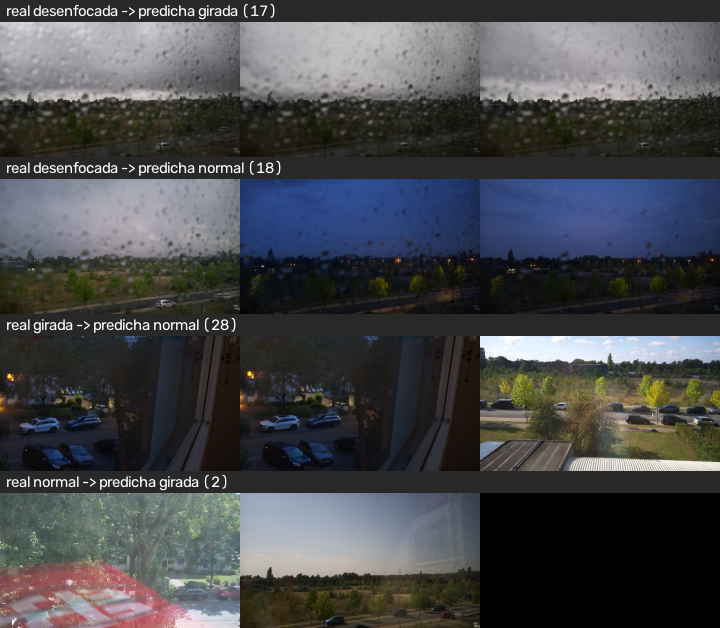

In [4]:
display(Image(filename=str(FIGURES / 'errores_ejemplos.png')))

## 3. Causa de cada tipo de error (cámara no vista)

Cada error se explica con la rama del árbol que lo decidió. La tabla sale directo de `errores_camara_no_vista.csv`, así que los números no se escriben a mano: `margen` = valor − umbral del descriptor decisivo. En `girada → normal` y `desenfocada → normal` el descriptor decisivo es `angle` y el margen es negativo: es lo que le faltó al ángulo para superar `angle_max` y marcar la imagen como girada.

In [5]:
errors = pd.read_csv(CLASSIC / 'errores_camara_no_vista.csv')
causes = (
    errors.assign(par=errors['label'] + ' → ' + errors['pred'])
    .groupby(['par', 'regla', 'descriptor_decisivo'])
    .agg(n=('path', 'size'), valor_mediano=('valor', 'median'), valor_max=('valor', 'max'),
         umbral=('umbral', 'first'), margen_mediano=('margen', 'median'))
    .round(3)
    .reset_index()
    .sort_values(['par', 'n'], ascending=[True, False])
)
causes

,par,regla,descriptor_decisivo,n,valor_mediano,valor_max,umbral,margen_mediano
2,desenfocada → girada,sin_coincidencias_y_nitida,lap_var,12,32.434,59.627,18.856,13.578
0,desenfocada → girada,coincide_pero_giro_grande,angle,3,83.760,154.480,0.940,82.820
1,desenfocada → girada,coincide_sin_angulo_fiable,angle,2,NaN,NaN,0.940,NaN
3,desenfocada → normal,coincide_y_giro_dentro_del_limite,angle,18,0.235,0.610,0.940,-0.704
4,girada → normal,coincide_y_giro_dentro_del_limite,angle,26,0.414,0.923,0.940,-0.526
5,normal → girada,coincide_pero_giro_grande,angle,1,0.951,0.951,0.940,0.011


Lectura: el árbol compara primero las coincidencias ORB con la referencia y después el ángulo. Los paneos pequeños (`girada → normal`) conservan coincidencias normales y su ángulo queda por debajo de `angle_max`, por eso el árbol los acepta como la misma vista. Estas causas salen de las ramas del árbol, no de comparar contra la mediana; antes de presentarlas en la defensa, mira las imágenes de la figura para confirmarlas.


In [6]:
pd.read_csv(CLASSIC / 'errores_camara_no_vista.csv').head(10)

,path,label,pred,regla,resultado,descriptor_decisivo,valor,umbral,margen
0,Location2_Blur/image_2024-09-04_18-19-00.jpg,desenfocada,girada,sin_coincidencias_y_nitida,girada,lap_var,59.627,18.856,40.771
1,Location2_Blur/image_2024-09-04_18-29-03.jpg,desenfocada,girada,sin_coincidencias_y_nitida,girada,lap_var,22.873,18.856,4.018
2,Location2_Blur/image_2024-09-04_18-39-06.jpg,desenfocada,girada,sin_coincidencias_y_nitida,girada,lap_var,57.072,18.856,38.216
3,Location2_Blur/image_2024-09-04_18-49-09.jpg,desenfocada,girada,sin_coincidencias_y_nitida,girada,lap_var,31.741,18.856,12.885
4,Location2_Blur/image_2024-09-04_18-59-11.jpg,desenfocada,girada,sin_coincidencias_y_nitida,girada,lap_var,30.086,18.856,11.230
5,Location2_Blur/image_2024-09-04_19-09-14.jpg,desenfocada,girada,sin_coincidencias_y_nitida,girada,lap_var,43.931,18.856,25.075
6,Location2_Blur/image_2024-09-04_19-19-17.jpg,desenfocada,girada,sin_coincidencias_y_nitida,girada,lap_var,31.515,18.856,12.659
7,Location2_Blur/image_2024-09-04_19-29-20.jpg,desenfocada,girada,sin_coincidencias_y_nitida,girada,lap_var,43.306,18.856,24.450
8,Location2_Blur/image_2024-09-04_19-39-22.jpg,desenfocada,normal,coincide_y_giro_dentro_del_limite,normal,angle,0.234,0.940,-0.706
9,Location2_Blur/image_2024-09-04_19-49-25.jpg,desenfocada,girada,sin_coincidencias_y_nitida,girada,lap_var,33.128,18.856,14.272
